In [1]:
# Generate comparison between NN, ZN, and TL
import numpy as np
import pandas as pd
from scipy.signal import find_peaks
from scipy.integrate import odeint
from simple_pid import PID
from tensorflow.keras.models import load_model

In [2]:
N_SYSTEMS = 500 # Number of randomly generated systems (Section 5.2.4.1)
SEED = 8 # Makes the random systems reproducible; remove to draw a new set each time
nn_file_name = 'nns_case1/prev_best_nn_13_10_400x' # Best Case 1 NN: 13 and 10 hidden nodes, 400 epochs (Section 5.3.1)
results_file = 'test_set_comp_data.csv'

# Range of each system variable (Table 11)
ranges = {'F': (0.5, 10.0), 'Cai': (5.0, 15.0), 'Fc': (0.0, 0.5), 'Cac': (100.0, 300.0)}

# Each variable is drawn uniformly between its minimum and maximum. The values are continuous, so the systems
# are separate from the grid used for the training and testing sets.
rng = np.random.default_rng(SEED)
randdf = pd.DataFrame({name: rng.uniform(low, high, N_SYSTEMS) for name, (low, high) in ranges.items()})

model = load_model(nn_file_name)

In [3]:
# define two tank system model
def two_tanks(x,t,ut,Cait,Ft,Cact,Ftott,Vt):

    # States (3):
    # Flowrate of correction stream (m3/min)
    Fc = x[0]
    # Conc. of tank 1 outlet (kg/m3)
    Ca1 = x[1]
    # Conc. of tank 2 outlet (kg/m3)
    Ca2 = x[2]

    # Parameters:
    # Kv - Valve gain (m3/(min*controller_out_units))
    Kv = 0.01
    
    # tauV - Valve constant (min)
    tauV = 0.1
    
    # Calculate valve derivative
    dFcdt = (Kv/tauV)*ut - (1/tauV)*Fc
    
    # Calculate concentration in tank 1 derivative
    dCa1dt = (Ft/Vt[0])*Cait + (Cact/Vt[0])*Fc - (Ftott/Vt[0])*Ca1
    
    # Calculate Concentration in tank 2 derivative
    dCa2dt = (Ftott/Vt[1])*Ca1 - (Ftott/Vt[1])*Ca2
    
    # Return xdot:
    xdot = np.zeros(3)
    xdot[0] = dFcdt
    xdot[1] = dCa1dt
    xdot[2] = dCa2dt
    return xdot

def step_change(F_sc, Cai_sc, Fc_sc, Cac_sc, Kp_sc, Ki_sc, Kd_sc):
    # Steady State Initial Condition/Constants
    # Again, we'll treat as zero for now. We can investigate chaning later.
    # Controller output steady state
    Kv_sc = 0.01
    
    u_sc = Fc_sc / Kv_sc

    # Volume of tank 1 and tank 2 (m3)
    V = np.empty(2)
    V[0] = 5
    V[1] = 4

    # Concentration of Initial Stream (kg/m3)
    Cai_ss = Cai_sc

    # Concentration of Correction Stream (kg/m3)
    Cac_ss = Cac_sc

    # Inlet Flowrate Initial Steady State (m3/min)
    F_ss = F_sc

    # Correction Stream Initial Steady State (m3/min)
    Fc_ss = Fc_sc

    # Total flowrate (m3/min)
    Ftot = F_sc + Fc_sc

    # Time Interval (min)
    t = np.linspace(0,50,2001)

    # System Parameters

    # Disturbance Variables (deviation form)
    # Inlet Concentration (kg/m^3)
    Cai = np.ones(len(t)) * Cai_sc

    # Inlet Flowrate (m3/min)
    F = np.ones(len(t)) * F_sc

    # Initial Concentration of Tank 1 and of Tank 2 (kg/m3)
    Ca1_sc = Ca2_sc = (F_sc * Cai_sc + Fc_sc * Cac_sc) / Ftot

    # Correction Stream Flowrate (m3/min)
    # See "Store results for plotting"

    # Store results for plotting
    Cai = np.ones(len(t)) * Cai_sc
    Cac = np.ones(len(t)) * Cac_sc
    F = np.ones(len(t)) * F_sc
    Fc = np.ones(len(t)) * Fc_sc
    Ca1 = np.ones(len(t)) * Ca1_sc
    Ca2 = np.ones(len(t)) * Ca2_sc
    u = np.ones(len(t)) * u_sc

    # Declare vector to pass
    x0 = np.empty(3)
    x0[0] = Fc_sc
    x0[1] = Ca1_sc
    x0[2] = Ca2_sc

    # setpoint
    sp = np.ones(len(t)) * (Ca2_sc + 1)
    u_bias = u_sc

    # create PID controller
    # op = op_bias + Kc * e + Ki * ei + Kd * ed
    #      with ei = error integral
    #      with ed = error derivative
    pid = PID(Kp_sc,Ki_sc,Kd_sc)

#     umin = 0
#     umax = 5
#     pid.output_limits = (umin-u_bias,umax-u_bias)

    # Simulate tank system ********
    for i in range(len(t)-1):
        # PID control
        pid.setpoint=sp[i] # Constantly updating setpoint!!!!!

        u[i+1] = pid(Ca2[i], t[i+1]-t[i]) + u_bias # The controller output becomes the input - uco???
        ts = [t[i],t[i+1]]
        y = odeint(two_tanks,x0,ts,args=(u[i+1],Cai[i],F[i],Cac[i],Ftot,V))
        
        #NOT ROUNDING led to crazy fluctuations at very small decimal places
        Fc[i+1] = round(y[-1][0], 5)
        Ca1[i+1] = round(y[-1][1], 5)
        Ca2[i+1] = round(y[-1][2], 5)
        x0[0] = Fc[i+1]
        x0[1] = Ca1[i+1]
        x0[2] = Ca2[i+1]

        Ftot = F[i+1] + Fc[i+1]

    return Ca2, t

In [4]:
# Step response used in the critical gain search: tauI = TAU_I_CG (10,000) and tauD = 0
def search_response(F_sr, Cai_sr, Fc_sr, Cac_sr, Kp_sr):
    return step_change(F_sr, Cai_sr, Fc_sr, Cac_sr, Kp_sr, 0, 0)

# Critical gain search starting from Kp = 1
def critical_gain(F_cg, Cai_cg, Fc_cg, Cac_cg):
    Kp_cg = 1

    fmax = -1
    lmax = 0
    #If there are no maxima in the output response curve:

    while abs(fmax - lmax) > 0.05:
        yout_cg, _ = search_response(F_cg, Cai_cg, Fc_cg, Cac_cg, Kp_cg) #Get the step response
        if yout_cg[find_peaks(yout_cg)[0]].size == 0:
            Kp_cg = Kp_cg*2
        #If there is only one maxima in the output response curve:
        elif yout_cg[find_peaks(yout_cg)[0]].size == 1:
            Kp_cg = Kp_cg*2
        #If there are multiple maxima in the output response curve:
        else:
            fmax = yout_cg[find_peaks(yout_cg)[0]][0]
            lmax = yout_cg[find_peaks(yout_cg)[0]][-1]
            # Use bisection method to get critical gain
            crit_gain = bisector(Kp_cg, fmax, lmax, F_cg, Cai_cg, Fc_cg, Cac_cg)
            return crit_gain

def bisector(Kp_ub, first_max, last_max, F_ub, Cai_ub, Fc_ub, Cac_ub):
    lower_bound = Kp_ub
    upper_bound = 0 # For initialization, set upper bound to 0

    while upper_bound == 0:
        if first_max > last_max:
            lower_bound = Kp_ub
            Kp_ub = Kp_ub + 3
            yout_ub, _ = search_response(F_ub, Cai_ub, Fc_ub, Cac_ub, Kp_ub) #Get the step response
            first_max = yout_ub[find_peaks(yout_ub)[0]][0]
            last_max = yout_ub[find_peaks(yout_ub)[0]][-1]
        elif first_max < last_max:
            upper_bound = Kp_ub
        elif first_max == last_max:
            return Kp_ub

    return bisect_critical_gain(lower_bound, upper_bound, first_max, last_max, F_ub, Cai_ub, Fc_ub, Cac_ub)

### Set tolerance for having determined critical gain
def bisect_critical_gain(lower_bound, upper_bound, first_max, last_max, F_bs, Cai_bs, Fc_bs, Cac_bs):
    Kp_bs = upper_bound
    while abs(first_max - last_max) > 0.05:
        Kp_bs = (upper_bound + lower_bound) / 2
        yout_bs, _ = search_response(F_bs, Cai_bs, Fc_bs, Cac_bs, Kp_bs) #Get the step response
        first_max = yout_bs[find_peaks(yout_bs)[0]][0]
        last_max = yout_bs[find_peaks(yout_bs)[0]][-1]
        if first_max > last_max:
            lower_bound = Kp_bs
        elif first_max < last_max:
            upper_bound = Kp_bs

    return Kp_bs

# Calculate ultimate period
def ultimate_period(cg_up, F_up, Cai_up, Fc_up, Cac_up):
    Kp_up = cg_up
    yout_up, t_up_repeat = search_response(F_up, Cai_up, Fc_up, Cac_up, Kp_up) #Get the step response
    peak1 = t_up_repeat[find_peaks(yout_up)[0]][0]
    peak2 = t_up_repeat[find_peaks(yout_up)[0]][1]
    p_ult = round(peak2 - peak1, 5)
    return p_ult

# # Bring overshoot below 8% (the process specification, Section 5.2.4.1) by heuristically adjusting tauI and tauD
# def check_overshoot(F_os, Cai_os, Fc_os, Cac_os, Kp_os, tauI_os, tauD_os):
#     Ki_os = Kp_os/tauI_os #Calculate Ki from tauI
#     Kd_os = Kp_os*tauD_os #Calculate Kd from tauD

#     yout_os, t_os_repeat = step_change(F_os, Cai_os, Fc_os, Cac_os, Kp_os, Ki_os, Kd_os) #Get the step response

#     Ca2_oss = (F_os * Cai_os + Fc_os * Cac_os) / (F_os + Fc_os)

#     cp_os = yout_os[find_peaks(yout_os)[0]][0]

#     new_Kd_os = Kd_os
#     new_tauI_os = tauI_os
#     add_tauI_os = 3
#     sub_tauI_os = 0.05
#     new_tauD_os = tauD_os
#     add_tauD_os = 0.05
#     sub_tauD_os = 0.01
#     while cp_os >= Ca2_oss + 1.08:
#         check1 = False
#         check2 = False
#         new_Ki_os = Kp_os/(new_tauI_os + add_tauI_os)
#         new_yout_os, _ = step_change(F_os, Cai_os, Fc_os, Cac_os, Kp_os, new_Ki_os, new_Kd_os) #Get the step response
#         cpIos = new_yout_os[find_peaks(new_yout_os)[0]][0]
#         if cpIos < cp_os:
#             cp_os = cpIos
#             new_tauI_os += add_tauI_os
#         elif cpIos > cp_os:
#             add_tauI_os = add_tauI_os / 2
#             new_Ki_os = Kp_os/(new_tauI_os - sub_tauI_os)
#             new_yout_os, _ = step_change(F_os, Cai_os, Fc_os, Cac_os, Kp_os, new_Ki_os, new_Kd_os) #Get the step response
#             new_cpIos = new_yout_os[find_peaks(new_yout_os)[0]][0]
#             if new_cpIos < cp_os:
#                 cp_os = new_cpIos
#                 new_tauI_os -= add_tauI_os
#             else:
#                 check1 = True
#         else:
#             check1 = True

#         new_Kd_os = Kp_os*(new_tauD_os + add_tauD_os)
#         new_yout_os, _ = step_change(F_os, Cai_os, Fc_os, Cac_os, Kp_os, new_Ki_os, new_Kd_os) #Get the step response
#         cpDos = new_yout_os[find_peaks(new_yout_os)[0]][0]
#         if cpDos < cp_os:
#             cp_os = cpDos
#             new_tauD_os += add_tauD_os
#         elif cpDos > cp_os:
#             new_KD_os = Kp_os*(new_tauD_os - sub_tauD_os)
#             new_yout_os, _ = step_change(F_os, Cai_os, Fc_os, Cac_os, Kp_os, new_Ki_os, new_Kd_os) #Get the step response
#             new_cpDos = new_yout_os[find_peaks(new_yout_os)[0]][0]
#             if new_cpDos < cp_os:
#                 cp_os = new_cpDos
#                 new_tauD_os -= add_tauD_os
#             else:
#                 check2 = True
#         else:
#             check2 = True
#         if check1 == True and check2 == True:
#             string_to_add_os = str(F_os) + ',' + str(Cai_os) + ',' + str(Fc_os) + ',' + str(Cac_os) + ',' + str(Kp_os) + ',' + str(new_tauI_os) + ',' + str(new_tauD_os) + ',' + str(cp_os)
#             f_os = open('failure_os_list.txt','a')
#             f_os.write(string_to_add_os + '\n')
#             f_os.close()
#             break
#     return round(new_tauI_os, 5), round(new_tauD_os, 5), round(Ca2_oss, 5), round(cp_os, 5)

# Ziegler-Nichols (ZN) and Tyreus-Luyben (TL) parameters from the critical gain and ultimate period, and the
# TL parameters with tauI and tauD adjusted to meet the overshoot specification (the values the training data would contain).
# Each set of parameters is returned as (Kp, tauI, tauD).
def heuristic_tunings(F_h, Cai_h, Fc_h, Cac_h):
    cg_h = critical_gain(F_h, Cai_h, Fc_h, Cac_h)
    ult_per = ultimate_period(cg_h, F_h, Cai_h, Fc_h, Cac_h)
    zn_h = (round(0.6 * cg_h, 5), round(ult_per / 2, 5), round(ult_per / 8, 5))
    tl_h = (round(0.45 * cg_h, 5), round(2.2 * ult_per, 5), round(ult_per / 6.3, 5))
#     tauI_adj, tauD_adj, _, _ = check_overshoot(F_h, Cai_h, Fc_h, Cac_h, *tl_h)
    return cg_h, ult_per, zn_h, tl_h #, (tl_h[0], tauI_adj, tauD_adj)

# Overshoot, settling time, and final value of a step response. The setpoint is 1 kg/m3 above the initial steady state.
def response_metrics(yout, t, setpoint):
    peaks = yout[find_peaks(yout)[0]]
    # Overshoot is the first maximum, the first peak, above the setpoint (0 if there is no overshoot)
    overshoot = max(peaks[0] - setpoint, 0) if peaks.size > 0 else 0.0
    # Settling time: look backwards along the curve for the last point which is more than 0.05 (5% of the step) from the final value
    outside_band = np.nonzero(np.abs(yout - yout[-1]) > 0.05)[0]
    st_index = outside_band[-1] if outside_band.size > 0 else 0
    return overshoot, t[st_index], yout[-1]

In [ ]:
# Column order of the results file
method_columns = ['Kp', 'tauI', 'tauD', 'overshoot', 'settling_time', 'final']
columns = ['F', 'Cai', 'Fc', 'Cac', 'Ca2_ss', 'ttl_spc_tm', 'critical_gain', 'ultimate_period'] \
          + [c + '_' + m for m in ('nn', 'zn', 'tl') for c in method_columns]
pd.DataFrame(columns=columns).to_csv(results_file, index=False)

# NN parameters for all of the systems at once
nn_params = model.predict(randdf[['F', 'Cai', 'Fc', 'Cac']], verbose=0)

for i in range(len(randdf)):
    if i % 25 == 0:
        print('system', i, 'of', len(randdf))

    #Obtain randomly generated parameters
    F, Cai, Fc, Cac = randdf.loc[i, ['F', 'Cai', 'Fc', 'Cac']]
    Ca2_ss = (F * Cai + Fc * Cac) / (F + Fc) # Initial steady state; the setpoint is 1 kg/m3 above it

    cg, ult_per, zn, tl = heuristic_tunings(F, Cai, Fc, Cac)

    # 'Kp', 'tauI', 'tauD' are the TL parameters adjusted to meet the overshoot specification (the training data targets)
    row = {'F': F, 'Cai': Cai, 'Fc': Fc, 'Cac': Cac, 'Ca2_ss': Ca2_ss, 'ttl_spc_tm': 9/(F+Fc),
           'critical_gain': cg, 'ultimate_period': ult_per} #, 'Kp': tuned[0], 'tauI': tuned[1], 'tauD': tuned[2]}

    methods = {'nn': tuple(float(p) for p in nn_params[i]), 'zn': zn, 'tl': tl}
    for name, (Kp_m, tauI_m, tauD_m) in methods.items():
        Ki_m = Kp_m/tauI_m
        Kd_m = Kp_m*tauD_m
        yout, t = step_change(F, Cai, Fc, Cac, Kp_m, Ki_m, Kd_m) #Get the step response
        overshoot_m, settling_time_m, final_m = response_metrics(yout, t, Ca2_ss + 1)
        row.update({'Kp_' + name: Kp_m, 'tauI_' + name: tauI_m, 'tauD_' + name: tauD_m,
                    'overshoot_' + name: overshoot_m, 'settling_time_' + name: settling_time_m, 'final_' + name: final_m})

    # Append each system as it finishes, so progress is kept if the run is interrupted
    pd.DataFrame([row])[columns].to_csv(results_file, mode='a', header=False, index=False)

In [5]:
# Compare results
data = pd.read_csv('test_set_comp_data.csv')
overshoot = data[['overshoot_nn', 'overshoot_zn', 'overshoot_tl']]
s_time = data[['settling_time_nn', 'settling_time_zn', 'settling_time_tl']]

In [9]:
nn_list_o = []
other_list_o = []
for i in range(len(overshoot)):
    if overshoot.loc[i]['overshoot_nn'] < overshoot.loc[i]['overshoot_zn'] and overshoot.loc[i]['overshoot_nn'] < overshoot.loc[i]['overshoot_tl']:
        nn_list_o.append(i)
    else:
        other_list_o.append(i)
        print('i =', i)
        print("nn overshoot:", overshoot.loc[i]['overshoot_nn'])
        print("tl overshoot:", overshoot.loc[i]['overshoot_tl'])
        print("zn overshoot:", overshoot.loc[i]['overshoot_zn'])

print('Number of times NN performs better:',len(nn_list_o))
print('Number of times NN performs worse:',len(other_list_o))
print(other_list_o)

i = 42
nn overshoot: 0.0936216766986959
tl overshoot: 0.062341676698697
zn overshoot: 0.5688016766986976
i = 192
nn overshoot: 0.0691235758807096
tl overshoot: 0.064353575880709
zn overshoot: 0.5685035758807118
i = 266
nn overshoot: 0.0924751501268943
tl overshoot: 0.0637251501268938
zn overshoot: 0.5727351501268938
i = 396
nn overshoot: 0.0855625675976625
tl overshoot: 0.0703325675976636
zn overshoot: 0.5826525675976626
i = 471
nn overshoot: 0.0785586155697082
tl overshoot: 0.063038615569706
zn overshoot: 0.5655686155697062
Number of times NN performs better: 495
Number of times NN performs worse: 5
[42, 192, 266, 396, 471]


In [13]:
nn_list_s = []
other_list_s = []
zn_list_s = []
for i in range(len(s_time)):
    if s_time.loc[i]['settling_time_nn'] < s_time.loc[i]['settling_time_zn'] and s_time.loc[i]['settling_time_nn'] < s_time.loc[i]['settling_time_tl']:
        nn_list_s.append(i)
    elif s_time.loc[i]['settling_time_nn'] > s_time.loc[i]['settling_time_zn']:
        zn_list_s.append(i)
        other_list_s.append(i)
#         print("i =", i)
#         print("nn st:", s_time.loc[i]['settling_time_nn'])
#         print("zn st:", s_time.loc[i]['settling_time_zn'])
    else:
        other_list_s.append(i)

print('Number of times NN performs better:',len(nn_list_s))
print('Number of times NN performs worse:',len(other_list_s))
print('Number of times ZN performs better:',len(zn_list_s))
print(zn_list_s)

Number of times NN performs better: 319
Number of times NN performs worse: 181
Number of times ZN performs better: 93
[3, 14, 41, 46, 66, 69, 80, 83, 90, 100, 106, 113, 114, 115, 121, 129, 131, 133, 134, 140, 144, 147, 162, 165, 171, 176, 177, 178, 184, 188, 190, 193, 200, 201, 207, 213, 217, 220, 221, 222, 226, 228, 230, 233, 248, 249, 259, 260, 261, 271, 278, 279, 280, 285, 290, 295, 298, 300, 308, 315, 316, 322, 323, 324, 325, 329, 330, 345, 349, 350, 352, 354, 360, 369, 371, 380, 384, 385, 390, 393, 397, 402, 406, 407, 410, 436, 442, 445, 467, 469, 480, 482, 498]


In [14]:
nn_list_s = []
other_list_s = []
tl_list_s = []
for i in range(len(s_time)):
    if s_time.loc[i]['settling_time_nn'] < s_time.loc[i]['settling_time_zn'] and s_time.loc[i]['settling_time_nn'] < s_time.loc[i]['settling_time_tl']:
        nn_list_s.append(i)
    elif s_time.loc[i]['settling_time_nn'] > s_time.loc[i]['settling_time_tl']:
        tl_list_s.append(i)
        other_list_s.append(i)
#         print("i =", i)
#         print("nn st:", s_time.loc[i]['settling_time_nn'])
#         print("tl st:", s_time.loc[i]['settling_time_tl'])
    else:
        other_list_s.append(i)

print('Number of times NN performs better:',len(nn_list_s))
print('Number of times NN performs worse:',len(other_list_s))
print('Number of times TL performs better:',len(tl_list_s))
print(tl_list_s)

Number of times NN performs better: 319
Number of times NN performs worse: 181
Number of times TL performs better: 179
[3, 4, 14, 19, 20, 28, 30, 37, 38, 41, 46, 52, 53, 55, 66, 69, 71, 79, 80, 83, 85, 90, 93, 94, 95, 97, 100, 102, 106, 108, 113, 114, 115, 116, 117, 118, 121, 128, 129, 130, 131, 133, 134, 138, 140, 142, 144, 146, 147, 151, 152, 162, 165, 167, 168, 171, 174, 176, 177, 178, 184, 185, 188, 190, 192, 193, 196, 200, 201, 205, 207, 209, 211, 213, 216, 217, 220, 221, 222, 223, 226, 227, 228, 230, 233, 239, 243, 248, 249, 252, 253, 257, 259, 260, 261, 270, 271, 278, 279, 280, 283, 285, 290, 293, 294, 295, 298, 300, 303, 308, 311, 313, 315, 316, 322, 323, 324, 325, 326, 329, 330, 336, 338, 345, 349, 350, 352, 354, 360, 362, 368, 369, 370, 371, 372, 373, 377, 380, 381, 384, 385, 386, 390, 393, 397, 398, 402, 403, 404, 406, 407, 410, 417, 418, 426, 427, 429, 431, 432, 435, 436, 442, 445, 453, 458, 459, 460, 467, 469, 471, 472, 474, 480, 482, 487, 490, 491, 497, 498]


In [15]:
# Ratios of the ZN and TL overshoots to the NN overshoot. Systems in which any overshoot is exactly 0 are skipped.
nonzero = (overshoot > 0).all(axis=1)
zn_list_compare_o = (overshoot['overshoot_zn'] / overshoot['overshoot_nn'])[nonzero].round(3).tolist()
tl_list_compare_o = (overshoot['overshoot_tl'] / overshoot['overshoot_nn'])[nonzero].round(3).tolist()
print(len(overshoot) - nonzero.sum(), 'systems skipped because an overshoot was 0')
print(max(tl_list_compare_o), '- biggest tl/nn ratio')
print((1 / min(tl_list_compare_o)), '- biggest nn/tl ratio')
print(min(tl_list_compare_o))
# print(zn_list_compare_o)
# print(tl_list_compare_o)

183 systems skipped because an overshoot was 0
145.942 - biggest tl/nn ratio
1.5015015015015014 - biggest nn/tl ratio
0.666


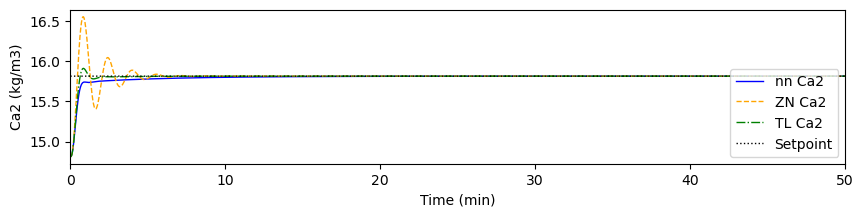

In [6]:
import matplotlib.pyplot as plt

i = 3 # Chosen as a trial in which settling time was less than 
nn_Ca2, nn_t = step_change(data.iloc[int(i)]['F'], data.iloc[int(i)]['Cai'], data.iloc[int(i)]['Fc'], data.iloc[int(i)]['Cac'], data.iloc[int(i)]['Kp_nn'], data.iloc[int(i)]['Kp_nn']/data.iloc[int(i)]['tauI_nn'], data.iloc[int(i)]['Kp_nn']*data.iloc[int(i)]['tauD_nn'])
zn_Ca2, zn_t = step_change(data.iloc[int(i)]['F'], data.iloc[int(i)]['Cai'], data.iloc[int(i)]['Fc'], data.iloc[int(i)]['Cac'], data.iloc[int(i)]['Kp_nn'], data.iloc[int(i)]['Kp_zn']/data.iloc[int(i)]['tauI_zn'], data.iloc[int(i)]['Kp_nn']*data.iloc[int(i)]['tauD_zn'])
tl_Ca2, tl_t = step_change(data.iloc[int(i)]['F'], data.iloc[int(i)]['Cai'], data.iloc[int(i)]['Fc'], data.iloc[int(i)]['Cac'], data.iloc[int(i)]['Kp_nn'], data.iloc[int(i)]['Kp_tl']/data.iloc[int(i)]['tauI_tl'], data.iloc[int(i)]['Kp_nn']*data.iloc[int(i)]['tauD_tl'])
plt.figure(figsize=(10,2))  
# Plot the results
plt.plot(nn_t,nn_Ca2,'b-',linewidth=1)
plt.plot(nn_t,zn_Ca2,'--',color='orange',linewidth=1)
plt.plot(nn_t,tl_Ca2,'g-.',linewidth=1)
plt.plot(nn_t,np.ones(len(nn_t))*(data['Ca2_ss'].iloc[i]+1),'k:',linewidth=1)

# plt.plot([t[0],t[-1]],[1.0,1.0],'k-',linewidth=1)
# plt.plot([t[0],t[-1]],[1.1,1.1],'k-',linewidth=1)
plt.ylabel('Ca2 (kg/m3)')
plt.xlabel('Time (min)')
plt.xlim(0, nn_t[-1])
plt.legend(['nn Ca2','ZN Ca2','TL Ca2', 'Setpoint'],loc='lower right')